# Global Food & Nutrition Database


### Descarga de los archivos

In [25]:
!pip install wget
!pip install pandas
!pip install matplotlib
!pip install scipy
!pip install sweetviz


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [26]:
from wget import download
from os import path, listdir
import pandas as pd
import numpy as np

if not path.exists("data/global_food.csv"):
    download("", out="data/global_food.csv")
else:
    print("Archivo ya descargado")

dfOG = pd.read_csv("data/global_food.csv", encoding='utf-8')

dfOG.head()

Archivo ya descargado


,product_name,brands,categories,ingredients,nutriscore_grade,nova_group,ecoscore_grade,allergens,energy_kcal,fat_100g,...,proteins_100g,salt_100g,sodium_100g,contains_gluten,contains_dairy,contains_nuts,contains_soy,contains_eggs,contains_fish,food_type
0,Sidi Ali,سيدي علي,"en:beverages-and-beverages-preparations, en:be...",OBD1 999 999 1112606 266963207 mb,A,NaN,NOT-APPLICABLE,NaN,0.0,0.0,...,0.0,0.000000,0.000000,False,False,False,False,False,False,Branded/Packaged
1,Perly,Perly,"en:dairies, en:fermented-foods, en:fermented-m...","milk cream, cream, sugar, banana, bacteria",UNKNOWN,3.0,B,"en:banana, en:milk",97.0,3.0,...,8.0,NaN,NaN,False,True,False,False,False,False,Branded/Packaged
2,Sidi Ali,Sidi Ali,"en:beverages-and-beverages-preparations, en:be...","Sodium, Calcium, Magnésium, Potassium, Bicarbo...",A,1.0,NOT-APPLICABLE,NaN,NaN,NaN,...,NaN,0.065000,0.026000,False,False,False,False,False,False,Branded/Packaged
3,Eau minérale naturelle,sidi ali,"en:beverages-and-beverages-preparations, en:be...",100% mineral water,A,1.0,NOT-APPLICABLE,NaN,NaN,NaN,...,NaN,0.065000,0.026000,False,False,False,False,False,False,Branded/Packaged
4,اكوافينا,AQUAFINA,"en:beverages-and-beverages-preparations, en:be...",ouverture et avant le : Voir bouteille. après ...,A,NaN,NOT-APPLICABLE,NaN,0.0,0.0,...,0.0,0.000508,0.000203,False,False,False,False,False,False,Branded/Packaged


In [27]:
dfOG.info(verbose=True, show_counts=True)
dfOG.describe()

<class 'pandas.DataFrame'>
RangeIndex: 4997 entries, 0 to 4996
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   product_name        4785 non-null   str    
 1   brands              4751 non-null   str    
 2   categories          4913 non-null   str    
 3   ingredients         4797 non-null   str    
 4   nutriscore_grade    4983 non-null   str    
 5   nova_group          4522 non-null   float64
 6   ecoscore_grade      4984 non-null   str    
 7   allergens           3332 non-null   str    
 8   energy_kcal         4682 non-null   float64
 9   fat_100g            4695 non-null   float64
 10  saturated_fat_100g  4617 non-null   float64
 11  carbs_100g          4676 non-null   float64
 12  sugars_100g         4631 non-null   float64
 13  fiber_100g          3495 non-null   float64
 14  proteins_100g       4690 non-null   float64
 15  salt_100g           4653 non-null   float64
 16  sodium_100g      

,nova_group,energy_kcal,fat_100g,saturated_fat_100g,carbs_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g
count,4522.000000,4682.000000,4695.000000,4617.000000,4676.000000,4631.000000,3.495000e+03,4690.000000,4653.000000,4653.000000
mean,3.278859,301.225402,15.997065,5.489583,32.598284,12.368927,1.748567e+09,7.348264,1.477237,0.590895
std,1.033540,221.661070,21.974815,12.451133,133.906873,22.020440,1.033727e+11,11.135688,14.776243,5.910491
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000
25%,3.000000,99.000000,1.500000,0.300000,4.800000,1.095000,5.000000e-01,1.700000,0.030000,0.012000
50%,4.000000,295.000000,7.420000,1.500000,19.700000,4.300000,3.000000e+00,6.300000,0.312000,0.125000
75%,4.000000,456.000000,23.000000,6.800000,58.000000,16.000000,6.600000e+00,9.600000,1.000000,0.400000
max,4.000000,5280.000000,554.000000,595.000000,8989.000000,895.000000,6.111242e+12,597.000000,898.000000,359.200000


In [34]:
df = dfOG.copy()

print("Filas antes de limpiar:", len(df))

# eliminamos la columna food type poruqe en todas las filas es el mismo valor
df = df.drop(columns=["food_type"])

# eliminamos las filas que tengan nombre y marca vacios
df = df.dropna(subset=['product_name', 'brands'], how='all')

# eliminamos las columnas repetidas
df.drop_duplicates(inplace=True)

# eliminamos las filas que tengan macros imposibles
macros = [
    "fat_100g", "saturated_fat_100g",
    "carbs_100g", "sugars_100g",
    "fiber_100g", "proteins_100g",
    "salt_100g", "sodium_100g"
]

fuera_rango = (
    df[macros].lt(0) | df[macros].gt(100)
).any(axis=1)

calorias_invalidas = (
    df["energy_kcal"].lt(0) | df["energy_kcal"].gt(900)
)

grasas_invalidas = (
    df["saturated_fat_100g"] > df["fat_100g"]
)

azucares_invalidos = (
    df["sugars_100g"] > df["carbs_100g"]
)

eliminar = (
    fuera_rango |
    calorias_invalidas |
    grasas_invalidas |
    azucares_invalidos
)

# Transformamos las variables cualitativas ordinales a numeros y la agregamos a columnas nuevas (no sabemos si eliminar las anteriores)
notasNutriscore = {"A": 1, "B": 2, "C": 3, "D": 4, "E": 5}
df["nutriscore_num"] = df["nutriscore_grade"].map(notasNutriscore)

notasEcoscore = {"A-PLUS": 1, "A": 2, "B": 3, "C": 4, "D": 5, "E": 6, "F": 7}
df["ecoscore_num"] = df["ecoscore_grade"].map(notasEcoscore)


print("Filas a eliminar:", eliminar.sum())

df = df.loc[~eliminar].copy()

print("Filas despues de limpiar:", len(df))


#Creamos la columna de categories_list, donde limpiamos cada categoria y las almacenamos en una lista

# Hacemos lo mismo con los alergenos, para facilitar su limpieza y la cuenta de cuantos
# hay presentes. Creamos allergens normalized y creamos grupos entre alergenos para poder
# sortear los problemas de tener alergenos en varios idiomas. 


df["categories"] = df["categories"].fillna("").apply(
    lambda x: list(dict.fromkeys(
        cat.strip().split(":", 1)[-1]
        for cat in x.split(",") if cat.strip()
    ))
)

df["allergens"] = df["allergens"].fillna("").apply(
    lambda x: list(dict.fromkeys(
        cat.strip().split(":", 1)[-1]
        for cat in x.split(",") if cat.strip()
    ))
)

#alergenos_unicos = sorted(df["allergens"].explode().dropna().unique())

#print(alergenos_unicos)
#print("Cantidad:", len(alergenos_unicos))

grupos_alergenos = {
    "milk": [
        "milk", "lait", "laitier", "leite", "milch",
        "laktose", "butterfat", "butterreinfett",
        "creme-laitiere", "crème", "cultured-nonfat-milk",
        "magermilchpulver", "mantequilla", "milcheiweiss",
        "molkeneiweisisolat", "molkeneiweißisolat",
        "molkeneweißkonzentrat", "vollmilchpulver",
        "amendoins-e-leite"
    ],

    "gluten": [
        "gluten", "gluten-de-ble", "cereals-with-gluten",
        "ble", "blé", "ble-avoine", "ble-d-epeautre",
        "avena", "avoine",
        "avoine-ou-hybrides-et-produits-a-base-de-ces-cereales",
        "buzagluten", "buzaliszt", "dinkelweizenmehl",
        "haferbasis", "oatbran", "orge", "seigle",
        "trigo-espelta", "triticale", "weizenmehl",
        "weizenstarke", "wheatberries",
        "pode-conter-vestigios-de-outros-cereais-com-gluten"
    ],

    "eggs": [
        "eggs", "oeuf", "oeufs", "œufs",
        "huhnereieiweisspulver", "huhnervollei",
        "hühnerei-trockeneiweiss"
    ],

    "nuts": [
        "nuts", "amandes", "amandes-amygdalus-communis-l",
        "mandeln", "hazlenuts", "noisettes",
        "noisettes-corylus-avellana",
        "fruits-a-coque", "fruits-à-coque",
        "frutos-de-casca-rija", "nusskernmischung",
        "pistaches-pistacia-vera",
        "noix-de-pecan-et-produits-a-base-de-noix-de-pecan-carya-illinoiesis-wangenh-k-koch",
        "noix-du-bresil-et-produits-a-base-de-noix-du-bresil-bertholletia-excelsa",
        "et-produits-a-base-de-ces-noix-macadamia-ternifolia",
        "puede-contener-trazas-de-frutos-de-cascara-y-o-de-soja"
    ],

    "peanuts": [
        "peanuts", "arachides", "cacahuetes",
        "select-roasted-peanuts", "amendoins-e-leite"
    ],

    "soybeans": [
        "soybeans", "sojabasis", "sojasaucenpulver",
        "kuoritut-soijapavut",
        "puede-contener-trazas-de-frutos-de-cascara-y-o-de-soja"
    ],

    "celery": [
        "celery", "celeri"
    ],

    "mustard": [
        "mustard", "moutarde"
    ],

    "sesame": [
        "sesame-seeds"
    ],

    "fish": [
        "fish"
    ],

    "crustaceans": [
        "crustaceans"
    ],

    "molluscs": [
        "molluscs"
    ],

    "lupin": [
        "lupin"
    ],

    "sulphites": [
        "sulphur-dioxide-and-sulphites",
        "anhydride-sulfureux-et-sulfites",
        "metabisulfito-sódico", "metabisulphite",
        "sodium-metabisulphite"
    ]
}

grupos_categorias = {
    "sauces": [
        "sauces", "algerian-style-sauces", "american-style-sauces",
        "barbecue-sauces", "brown-sauces", "burger-sauces",
        "cooking-sauces", "curry-sauces", "harissa-sauces",
        "hot-sauces", "indian-style-sauces", "mayonnaises",
        "meal-sauces", "meat-based-sauces", "nuoc-mam-sauce",
        "oyster-sauces", "pasta-sauces", "pestos", "pizza-sauces",
        "salad-dressings", "sauce-biggy", "sauces-andalouses",
        "soy-sauces", "tacos-sauce", "tartare-sauces",
        "tomato-sauces", "tzatzikis", "vegetarian-sauces",
        "worcestershire-sauces"
    ],

    "beverages": [
        "beverages", "beverages-and-beverages-preparations",
        "beverage-preparations", "boissons", "boisson-soda",
        "boissons-aux-fruits", "non-alcoholic-beverages",
        "carbonated-drinks", "sodas", "soft-drinks",
        "artificially-sweetened-beverages", "sweetened-beverages",
        "energy-drinks", "energy-drink-with-sugar", "sportdrank",
        "coca-cola", "sprite", "juice", "waters", "spring-waters",
        "table-waters", "herbal-teas", "iced-teas",
        "tea-based-beverages", "coffees", "hot-beverages",
        "instant-beverages", "plant-based-beverages",
        "alcoholic-beverages", "beers", "aperitif", "مشروب"
    ],

    "dairies": [
        "dairies", "milks", "laits", "laits-fluide-et-poudre",
        "laits-uht", "milks-liquid-and-powder", "semi-skimmed-milks",
        "homogenized-milks", "condensed-milks", "evaporated-milks",
        "evaporated-milks-with-sugar", "evaporated-milks-without-sugar",
        "fermented-milk-products", "dairy-drinks", "dairy-desserts",
        "dairy-variety-packs", "creams", "compound-dairy-creams",
        "cremes-allegees-en-matiere-grasse", "cremes-fraiches",
        "cremes-legeres", "creme-cuisson", "creme-fromagere",
        "uht-creams", "uht-compound-dairy-creams-with-4-to-8-fat",
        "whipped-creams", "yaourt-a-boire-aux-fruits",
        "yaourt-veloute-pistache", "danoune", "ياغورت"
    ],

    "snacks": [
        "snacks", "salty-snacks", "sweet-snacks",
        "vegetarian-snacks", "snacks-sales", "bars",
        "protein-bars", "barre-de-cereales-a-la-creme-de-lait",
        "frozen-fried-potatoes", "popcorn", "corn-snack",
        "chips-and-fries", "pastry-snack", "appetizers"
    ],

    "desserts_and_sweets": [
        "desserts", "frozen-desserts", "chocolate-desserts",
        "sweet-mousses", "biscuits-and-cakes", "galletas",
        "gateau-fourre-chocolat", "sweet-pastries-and-pies",
        "confectioneries", "puddings", "rice-puddings",
        "dessert-mixes", "preparations-pour-flans",
        "creme-dessert-riche-en-proteines", "γλυκό",
        "cocoa-and-its-products", "cocoa-powders",
        "cocoa-and-chocolate-powders", "cacao-nibs",
        "crepes", "crepes-and-galettes", "crepes-et-galettes",
        "crepes-de-froment", "pancakes"
    ],

    "cereals_and_starches": [
        "cereals-and-potatoes", "cereales-completes",
        "cereales-et-derives", "cereales-preparees",
        "flakes", "cruesli", "sourdough",
        "sourdough-bread", "seeded-bread", "crumpet",
        "crumpets", "warburtons-crumpets", "midi-flatbread",
        "pastas", "tortillas-avoine-et-ble"
    ],

    "meats": [
        "meats", "meats-and-their-products", "meat-preparations",
        "prepared-meats", "beef-and-its-products",
        "pork-and-its-products", "chicken-and-its-products",
        "charcuteries-cuites", "hams", "sausages", "poultries"
    ],

    "seafood": [
        "seafood", "fishes", "fishes-and-their-products",
        "fish-preparations"
    ],

    "prepared_meals": [
        "meals", "refeicoes", "meals-with-meat", "meals-with-fish",
        "microwave-meals", "refeicoes-para-micro-ondas",
        "pasta-dishes", "rice-dishes", "prepared-rices",
        "prepared-couscous", "prepared-salads", "tabbouleh",
        "chicken-tabbouleh", "pizzas", "pizzas-pies-and-quiches",
        "quiches", "gratins", "dumplings", "korean-dumplings",
        "spanish-omelettes", "potato-dishes",
        "savory-semolina-dishes", "falafels", "stuffed-vine-leaves",
        "poultry-sandwiches", "sandwiches", "breaded-products",
        "cod-brandade", "beef-dishes", "stuffing"
    ],

    "plant_based": [
        "plant-based-foods", "plant-based-foods-and-beverages",
        "alimentos-de-origen-vegetal", "aliments-d-origine-vegetale",
        "aliments-et-boissons-a-base-de-vegetaux",
        "vegan", "vegan-products", "vegetarisch",
        "dairy-substitutes", "plant-based-creams",
        "plantaardige-kaas", "plantaardige-kaas-voor-maaltijden",
        "meat-alternatives", "meat-analogues",
        "meat-analogues-from-soy-or-wheat-proteins",
        "prepared-meat-cuts-substitutes", "vegetarian-balls",
        "vegetarian-patties", "vegetarian-sausages",
        "tofu-patties", "tranches-vegetales",
        "cereals-and-vegetables-patties",
        "hamburguesas-vegetales-espinacas-y-zanahoria"
    ],

    "fruits_and_vegetables": [
        "fruits-and-vegetables-based-foods",
        "prepared-vegetables",
        "vegetables-prepared-processed-shelf-stable"
    ],

    "legumes": [
        "legumes-and-their-products"
    ],

    "nuts_and_seeds": [
        "nuts-and-their-products", "seeds"
    ],

    "eggs": [
        "eggs", "chicken-eggs"
    ],

    "soups_and_broths": [
        "soups", "reheatable-soups", "chicken-soups",
        "broths", "beef-broth", "chicken-stock", "bouillon-pots"
    ],

    "condiments": [
        "condiments", "mustards", "vinegars",
        "balsamic-vinegars", "cider-vinegars",
        "malt-vinegars", "white-vinegars", "wine-vinegars",
        "pickles", "salts", "sea-salts", "table-salts",
        "french-salts", "sels-fins", "herbs-and-spices"
    ],

    "sugars_and_sweeteners": [
        "sugars", "sweeteners", "sugar-substitutes",
        "edulcorants-sucres-sucres-en-poudre",
        "beet-sugars", "brown-sugars", "cane-sugar",
        "caster-sugars", "coconut-sugar", "granulated-sugars",
        "powdered-sugars", "vanilla-sugars", "vanillin-sugars",
        "syrups", "simple-syrups", "flavoured-syrups"
    ],

    "fats_and_oils": [
        "fats", "animal-fats", "oil",
        "huile-de-table", "spreadable-fats"
    ],

    "spreads": [
        "spreads", "sweet-spreads", "salted-spreads",
        "produits-a-tartiner", "produits-a-tartiner-sucres",
        "chocolat-a-tartiner", "yeast-extract-spreads"
    ],

    "breakfasts": [
        "breakfasts", "petit-dejeuners"
    ],

    "baby_foods": [
        "baby-foods", "baby-milks", "growth-milks",
        "biscuits-for-babies", "snacks-and-desserts-for-babies",
        "cerelac", "cerelac-pour-enfants", "enfants"
    ],

    "supplements": [
        "supplements", "dietary-supplements",
        "complements-alimentaires", "bodybuilding-supplements",
        "fitness-nutrition", "meal-replacements",
        "supplement-de-proteines", "creatine", "vitamins", "magnesio"
    ],

    "baking_and_ingredients": [
        "ingredients", "cooking-helpers", "pastry-helpers",
        "baking-mixes", "baking-powder",
        "baking-powder-or-raising-agent", "poudres-a-lever",
        "yeast", "baker-s-yeast", "dried-yeast",
        "nutritional-yeast", "food-additives", "flavors"
    ],

    "fermented_foods": [
        "fermented-foods"
    ],

    "preservation_labels": [
        "canned-foods", "dried-products",
        "dried-products-to-be-rehydrated", "frozen-foods",
        "refrigerated-foods", "fresh-foods"
    ]
}

equivalencias_alergenos = {}

for grupo, variantes in grupos_alergenos.items():
    for variante in variantes:
        equivalencias_alergenos.setdefault(variante, []).append(grupo)

df["allergens_normalized"] = df["allergens"].apply(
    lambda lista: list(dict.fromkeys(
        grupo
        for alergeno in lista
        for grupo in equivalencias_alergenos.get(alergeno, [])
    ))
)

df["allergens_count"] = df["allergens_normalized"].apply(len)

equivalencias_categorias = {}

for grupo, variantes in grupos_categorias.items():
    for variante in variantes:
        equivalencias_categorias.setdefault(variante, []).append(grupo)

df["categories_normalized"] = df["categories"].apply(
    lambda lista: list(dict.fromkeys(
        grupo
        for categoria in lista
        for grupo in equivalencias_categorias.get(categoria, [])
    ))
)

df.head(30)

####chequeo

# frecuencias = df["categories_normalized"].explode().value_counts()
#
# print(frecuencias.to_string())
# print("Cantidad de grupos:", len(frecuencias))
#
# sin_clasificar = sorted(
#     set(df["categories"].explode().dropna())
#     - set(equivalencias_categorias)
# )
#
# print(sin_clasificar)


Filas antes de limpiar: 4997
Filas a eliminar: 28
Filas despues de limpiar: 4871


,product_name,brands,categories,ingredients,nutriscore_grade,nova_group,ecoscore_grade,allergens,energy_kcal,fat_100g,...,contains_dairy,contains_nuts,contains_soy,contains_eggs,contains_fish,nutriscore_num,ecoscore_num,allergens_normalized,allergens_count,categories_normalized
0,Sidi Ali,سيدي علي,"[beverages-and-beverages-preparations, beverag...",OBD1 999 999 1112606 266963207 mb,A,NaN,NOT-APPLICABLE,[],0.00000,0.0,...,False,False,False,False,False,1.0,NaN,[],0,[beverages]
1,Perly,Perly,"[dairies, fermented-foods, fermented-milk-prod...","milk cream, cream, sugar, banana, bacteria",UNKNOWN,3.0,B,"[banana, milk]",97.00000,3.0,...,True,False,False,False,False,NaN,3.0,[milk],1,"[dairies, fermented_foods]"
2,Sidi Ali,Sidi Ali,"[beverages-and-beverages-preparations, beverag...","Sodium, Calcium, Magnésium, Potassium, Bicarbo...",A,1.0,NOT-APPLICABLE,[],NaN,NaN,...,False,False,False,False,False,1.0,NaN,[],0,[beverages]
3,Eau minérale naturelle,sidi ali,"[beverages-and-beverages-preparations, beverag...",100% mineral water,A,1.0,NOT-APPLICABLE,[],NaN,NaN,...,False,False,False,False,False,1.0,NaN,[],0,[beverages]
4,اكوافينا,AQUAFINA,"[beverages-and-beverages-preparations, beverag...",ouverture et avant le : Voir bouteille. après ...,A,NaN,NOT-APPLICABLE,[],0.00000,0.0,...,False,False,False,False,False,1.0,NaN,[],0,[beverages]
5,Lait,Jaouda,"[dairies, meals, milks-liquid-and-powder]",Lait frais pasteurisé demi-écrémé à 15g/l de m...,B,3.0,D,[milk],45.00000,1.5,...,True,False,False,False,False,2.0,5.0,[milk],1,"[dairies, prepared_meals]"
6,Eau De Source,Cristaline,"[beverages-and-beverages-preparations, beverag...",Eau de source,A,1.0,NOT-APPLICABLE,[none],0.00000,0.0,...,False,False,False,False,False,1.0,NaN,[],0,[beverages]
7,Fromage Blanc Nature,Milky Food Professional,"[dairies, fermented-foods, fermented-milk-prod...","Ferments lactiques, Présure, Sel.",A,3.0,B,[milk],80.60000,12.0,...,True,False,False,False,False,1.0,3.0,[milk],1,"[dairies, fermented_foods]"
8,uht jaouda 1L,Jaouda,"[dairies, milks-liquid-and-powder, milks]",Lait entier,B,1.0,D,[milk],58.00000,3.0,...,True,False,False,False,False,2.0,5.0,[milk],1,[dairies]
9,Jben,Jaouda,"[dairies, fermented-foods, fermented-milk-prod...","lait frais entier, crème, stabilisants, amidon...",D,4.0,D,[milk],235.00000,21.0,...,True,False,False,False,False,4.0,5.0,[milk],1,"[dairies, fermented_foods]"


In [29]:
#import sweetviz as sv

#report = sv.analyze(df)
#report.show_notebook()

Los productos con gluten no superan el 50% (32.7%)


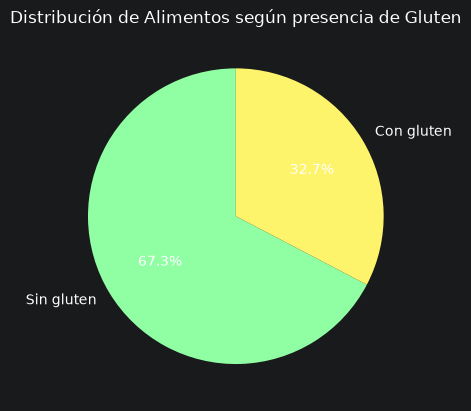

In [30]:
import matplotlib.pyplot as plt

# Validamos la primer hipotesis: Mas del 50% de los alimentos contienen gluten

proporcion_gluten = df["contains_gluten"].mean()

if (proporcion_gluten > 0.5):
    print(f"Los productos con gluten superan el 50% ({proporcion_gluten:.1%})")
else:
    print(f"Los productos con gluten no superan el 50% ({proporcion_gluten:.1%})")

conteo = df["contains_gluten"].map({True: 'Con gluten', False: 'Sin gluten'}).value_counts()

plt.pie(
    conteo, 
    labels=conteo.index,
    autopct='%1.1f%%',
    colors=["#90ffa4", "#fef46b"],
    startangle=90
)

plt.title('Distribución de Alimentos según presencia de Gluten')
plt.show()

Text(0, 0.5, 'sugars_100g')

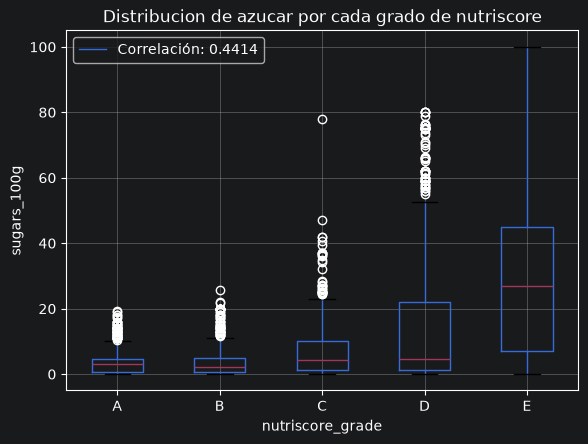

In [31]:
import scipy

# Validamos la segunda hipotesis: Los alimentos con mayor cantidad de azucar tienen un nutriscore mas bajo

df_h2 = df[["nutriscore_grade", "nutriscore_num", "sugars_100g"]].copy()

df_h2 = df_h2.dropna()

correlacion = df_h2[["sugars_100g", "nutriscore_num"]].corr(method="spearman").iloc[0, 1]

var1 = "nutriscore_grade"
var2 = "sugars_100g"

df_h2.boxplot(column=var2, by=var1)
plt.title("Distribucion de azucar por cada grado de nutriscore")
plt.legend([f"Correlación: {correlacion:.4f}"], loc="upper left")
plt.suptitle('')
plt.xlabel(var1)
plt.ylabel(var2)

Los productos con altas grasas saturadas superan el 25% (30.6%)


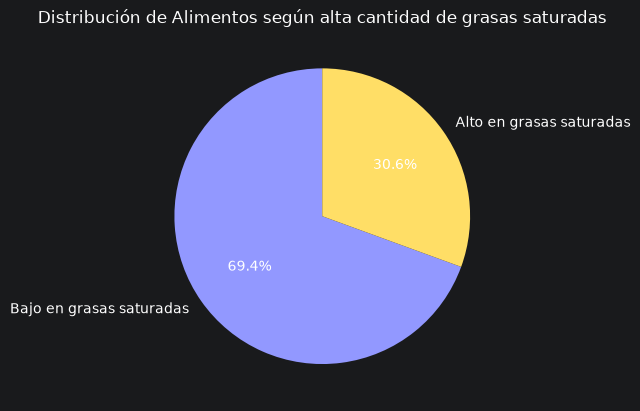

In [32]:
# Validacion de la primer hipotesis del enunciado

df_grasas = df["saturated_fat_100g"].dropna()
proporcion_grasas = (df_grasas > 5).mean()

if (proporcion_grasas > 0.25):
    print(f"Los productos con altas grasas saturadas superan el 25% ({proporcion_grasas:.1%})")
else:
    print(f"Los productos con altas grasas saturadas no superan el 25% ({proporcion_grasas:.1%})")

conteo = (df_grasas > 5).map({True: 'Alto en grasas saturadas', False: 'Bajo en grasas saturadas'}).value_counts()

plt.pie(
    conteo, 
    labels=conteo.index,
    autopct='%1.1f%%',
    colors=["#9298ff", "#ffde66"],
    startangle=90
)

plt.title('Distribución de Alimentos según alta cantidad de grasas saturadas')
plt.show()



Spearman: 0.31908106486591015
p-valor: 9.217120846021796e-99


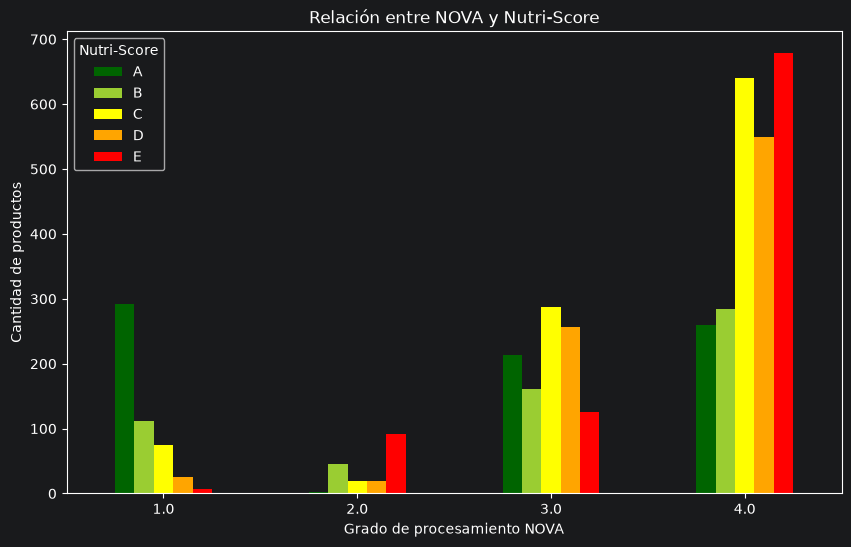

In [33]:
from scipy.stats import spearmanr

df_h5 = df[["nova_group", "nutriscore_num"]].copy()

df_h5 = df_h5.dropna()

coeficiente, p_valor = spearmanr(
    df_h5["nova_group"],
    df_h5["nutriscore_num"]
)

print("Spearman:", coeficiente)
print("p-valor:", p_valor)

####

tabla = pd.crosstab(
    df_h5["nova_group"],
    df_h5["nutriscore_num"]
)

tabla.plot(
    kind="bar",
    stacked=False,
    color=["darkgreen", "yellowgreen", "yellow", "orange", "red"],
    figsize=(10, 6)
)

plt.xlabel("Grado de procesamiento NOVA")
plt.ylabel("Cantidad de productos")
plt.title("Relación entre NOVA y Nutri-Score")
plt.legend(title="Nutri-Score", labels=["A", "B", "C", "D", "E"])
plt.xticks(rotation=0)
plt.show()

Medias y desviaciones estándar antes del escalado:
      nova_group  allergens_count
mean    3.294018         1.232272
std     1.014799         1.173216
Medias y desviaciones estándar después del escalado:
        nova_group  allergens_count
mean -2.056564e-16     1.713803e-18
std   1.000121e+00     1.000121e+00
                            OLS Regression Results                            
Dep. Variable:         nutriscore_num   R-squared:                       0.151
Model:                            OLS   Adj. R-squared:                  0.150
Method:                 Least Squares   F-statistic:                     367.5
Date:                Mon, 26 Oct 2026   Prob (F-statistic):          1.24e-147
Time:                        17:30:21   Log-Likelihood:                -6925.8
No. Observations:                4146   AIC:                         1.386e+04
Df Residuals:                    4143   BIC:                         1.388e+04
Df Model:                           2                 

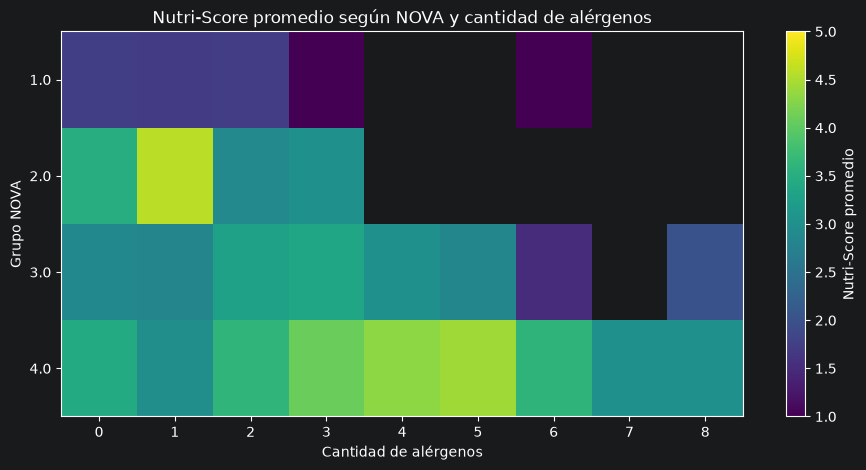

In [52]:
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm

scaler = StandardScaler()

# Seleccionamos las variables y eliminamos filas con NaN
df_h6 = df[["nova_group", "allergens_count", "nutriscore_num"]].dropna()

df_h6_X = df_h6[["nova_group", "allergens_count"]].copy()
df_h6_Y = df_h6["nutriscore_num"].copy()

X_scaled = scaler.fit_transform(df_h6_X)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=df_h6_X.columns,
    index=df_h6_X.index
)

print("Medias y desviaciones estándar antes del escalado:")
print(df_h6_X.describe().loc[['mean', 'std']])

print("Medias y desviaciones estándar después del escalado:")
print(X_scaled_df.describe().loc[['mean', 'std']])

X_scaled_df_ = sm.add_constant(X_scaled_df)

model = sm.OLS(df_h6_Y, X_scaled_df_).fit()
print(model.summary())

tabla = df_h6.pivot_table(
    index="nova_group",
    columns="allergens_count",
    values="nutriscore_num",
    aggfunc="mean"
)

plt.figure(figsize=(11, 5))
plt.imshow(tabla, cmap="viridis", aspect="auto", vmin=1, vmax=5)

plt.xticks(range(len(tabla.columns)), tabla.columns)
plt.yticks(range(len(tabla.index)), tabla.index)

plt.xlabel("Cantidad de alérgenos")
plt.ylabel("Grupo NOVA")
plt.title("Nutri-Score promedio según NOVA y cantidad de alérgenos")
plt.colorbar(label="Nutri-Score promedio")

plt.show()